# Discrete and smeared stringers: integrally stiffened Technion shells (Weller and Singer 1977; Poorveis and Kabir 2006)

How far is a model with discrete stringers from the smeared-stiffener theory
when the stringers are closely spaced? Weller and Singer [1] tested in axial
compression integrally stringer-stiffened 7075-T6 shells with the stringers
outside and give, for each shell, the non-dimensional stringer properties,
the load of the linear smeared-stiffener theory for the simple supports SS3
($w = M_x = N_x = v = 0$) and SS4 ($w = M_x = u = v = 0$) and the test load
(Table 1, p. 723). Poorveis and Kabir [2] analysed one of these shells
(AS-27M2, their case A) and a shell of Shen, Zhou and Chen (case D, test
from [3]) with a geometrically nonlinear Ritz model, with discrete and with
smeared stringers (Table 2, p. 119), and a third shell (case C, shell DUD-8
of [5]) under external pressure and combined loading.
The pressure is applied as a dead and as a live (follower) load, and case C
and case D are also studied under combined pressure and axial compression,
with the interaction curve of Shen, Zhou and Chen [3] for DUD-8. This notebook builds the shells as
`MultiDomain` assemblies with discrete blade stringers and compares with
these values, and with the smeared theory of Block, Card and Mikulas [4]
(equation (15), SS3, membrane pre-buckling state) evaluated for the section of
[1] (which reproduces the SS3 loads of [1]) and for the section of the
discrete model (the reference of the **discreteness gap**).

The AS-27 shells have a Koiter parameter $\theta > 0.64$, chosen by Weller and
Singer to study unstable postbuckling of the skin panels between the
stringers (p. 722); for AS-27M2 Poorveis and Kabir found the discrete value
30 % below the smeared one and attributed it to panel instability (p. 119).

[1] T. Weller and J. Singer, *Experimental studies on the buckling under
axial compression of integrally stringer-stiffened circular cylindrical
shells*, J. Appl. Mech. 44(4), 721-730, 1977, doi:10.1115/1.3424163.

[2] D. Poorveis and M. Z. Kabir, *Buckling of discretely stringer-stiffened
composite cylindrical shells under combined axial compression and external
pressure*, Scientia Iranica 13(2), 113-123, 2006.

[3] H.-S. Shen, P. Zhou and T.-Y. Chen, *Postbuckling analysis of stiffened
cylindrical shells under combined external pressure and axial compression*,
Thin-Walled Struct. 15(1), 43-63, 1993, doi:10.1016/0263-8231(93)90012-Y.

[4] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

[5] H. Abramovich, T. Weller and J. Singer, *Effect of sequence of combined
loading on buckling of stiffened shells*, Exp. Mech. 28(1), 1-13, 1988,
doi:10.1007/BF02328988.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
import stringer_cylinder_utils as su


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

def plot_mode(ax, md_, c, skin, R, title, ns, frac=1.):
    x, th, w = bu.skin_w(md_, c, skin, R)
    sel = th <= frac*th.max() + 1e-12
    ax.pcolormesh(np.degrees(th[sel]), x, (w[sel]/np.abs(w).max()).T, cmap='RdBu_r',
                  shading='auto', vmin=-1, vmax=1)
    pos = (np.arange(ns) + 0.5)*2*np.pi/ns
    pos = pos[pos <= th[sel].max()]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(r'$\theta$, deg')

## Shells, geometry and material

Table 1 of [1] (p. 723): skin thickness $h$, $R/h$, $L/R$, $-(e_1/h)$ ($e_1$
negative outside, Fig. 1), $A_1/(bh)$, $I_{11}/(bh^3)$ (about the centroid
of the stringer), $\eta_{t1} = G_1 I_{t1}/(bD)$ with $D = E h^3/(12(1 -
\nu^2))$, Koiter's parameter $\theta = [12(1 - \nu^2)]^{1/4} (b/2\pi)
(Rh)^{-1/2}$ (p. 722), the SS3 and SS4 smeared loads and the test load, in
kg (kilogram-force). $E = 0.75 \times 10^4$ kg/mm$^2$ (p. 724), $\nu = 0.30$
(p. 722). The spacing $b$ follows from $\theta$; $2\pi R/b$ gives the
number of stringers. Units here: mm and kg (force); $\bar{N}$ in kg/mm
(times 9.807 for N/mm). AS-26M1 to AS-26M3 are excluded, as by the authors
(footnote b); the SS4 load of AS-35 is misprinted (460 kg; $2850/0.610 = 4672$
kg from the printed ratio) and not used. The stringers are rectangles $t_s
\times h_s$: $h_s = \sqrt{12 I_{11}/A_1}$ reproduces $e_1 = (h + h_s)/2$ and
the torsion constant of the rectangle reproduces $I_{t1}$ (see the
bfsccylinder implementation of this case for the check).

In [2]:
E, NU, KGF = 0.75e4, 0.30, 9.80665
TABLE1 = {
    'AS-27M1': (0.195, 618, 0.648, 3.86, 0.760, 2.860, 23.50, 0.807, 4190, 3600),
    'AS-27M2': (0.204, 591, 0.652, 3.67, 0.717, 2.400, 19.84, 0.789, 4210, 3300),
    'AS-27M3': (0.202, 597, 0.650, 3.72, 0.729, 2.520, 20.83, 0.793, 4240, 3920),
    'AS-34': (0.254, 472, 1.080, 2.97, 0.533, 1.080, 5.75, 0.470, 3430, 2800),
    'AS-35': (0.250, 480, 1.080, 3.04, 0.549, 1.180, 6.11, 0.474, 3390, 2850),
}
# Poorveis and Kabir (2006), Table 1 (p. 119): L, R, h, n_s, A1/(b1 h), e1/h, I1/(b h^3), G1 J1/(b D)
# and Table 2: test, smeared, discrete (kg/mm)
POORVEIS_D = (130.00, 120.10, 0.254, 85, 0.590, 3.420, 1.680, 6.563)
POORVEIS_T2 = {'A': (4.356, 6.110, 4.250), 'D': (5.334, 5.370, 5.450)}
k4 = (12*(1 - NU**2))**0.25
G = E/(2*(1 + NU))


def shell(h, R, L, ns, A, I, e, J, P3=None, Pe=None):
    d = dict(h=h, R=R, L=L, ns=ns, b=2*np.pi*R/ns, A=A, I=I, e=e, J=J, P3=P3, Pe=Pe)
    d['hs'] = np.sqrt(12*I/A)
    d['ts'] = A/d['hs']
    d['Hs'] = d['hs'] + h/2
    d['Jplate'] = d['Hs']*d['ts']**3/3
    return d


shells = {}
rows = []
for s, (h, Rh, LR, e, Ab, Ib, eta, theta, P3, Pe) in TABLE1.items():
    R = Rh*h
    ns = int(round(2*np.pi*R/(theta*2*np.pi*np.sqrt(R*h)/k4)))
    b = 2*np.pi*R/ns
    D = E*h**3/(12*(1 - NU**2))
    shells[s] = shell(h, R, LR*R, ns, Ab*b*h, Ib*b*h**3, e*h, eta*b*D/G, P3, Pe)
L, R, h, ns, Ab, e, Ib, eta = POORVEIS_D
b = 2*np.pi*R/ns
shells['D'] = shell(h, R, L, ns, Ab*b*h, Ib*b*h**3, e*h, eta*b*E*h**3/(12*(1 - NU**2))/G)
for s, d in shells.items():
    rows.append([s, '%.3f' % d['h'], '%.2f' % d['R'], '%.2f' % d['L'], d['ns'], '%.3f' % d['ts'],
                 '%.3f' % d['hs'], '%.4f (%.4f)' % ((d['h'] + d['hs'])/2, d['e']),
                 '%.3f' % d['J'], '%.2f' % (d['J']/d['Jplate'])])
table(['shell', 'h, mm', 'R, mm', 'L, mm', 'n_s', 't_s, mm', 'h_s, mm', '(h + h_s)/2 (e_1), mm',
       'I_t1, mm^4', 'I_t1/J_plate'], rows)

| shell | h, mm | R, mm | L, mm | n_s | t_s, mm | h_s, mm | (h + h_s)/2 (e_1), mm | I_t1, mm^4 | I_t1/J_plate |
|---|---|---|---|---|---|---|---|---|---|
| AS-27M1 | 0.195 | 120.51 | 78.09 | 56 | 1.529 | 1.310 | 0.7527 (0.7527) | 0.561 | 0.33 |
| AS-27M2 | 0.204 | 120.56 | 78.61 | 56 | 1.530 | 1.293 | 0.7485 (0.7487) | 0.542 | 0.33 |
| AS-27M3 | 0.202 | 120.59 | 78.39 | 56 | 1.532 | 1.301 | 0.7515 (0.7514) | 0.553 | 0.33 |
| AS-34 | 0.254 | 119.89 | 129.48 | 84 | 0.969 | 1.252 | 0.7532 (0.7544) | 0.201 | 0.48 |
| AS-35 | 0.250 | 120.00 | 129.60 | 84 | 0.970 | 1.270 | 0.7598 (0.7600) | 0.204 | 0.48 |
| D | 0.254 | 120.10 | 130.00 | 85 | 0.896 | 1.485 | 0.8694 (0.8687) | 0.227 | 0.59 |

## Smeared-stiffener theory

Equation (15) of [4] (`su.smeared_ss`, minimum over $m \le 12$, $n \le 60$)
with the section of [1] reproduces the SS3 loads of [1]. The discrete model
represents a stringer by a plate strip from the middle surface of the skin to
the tip, $t_s \times H_s$, $H_s = h_s + h/2$; as a smeared section this strip
has $A = t_s H_s$, $\bar{z} = H_s/2$, $I_o = t_s H_s^3/3$ and the twisting
stiffness of a Kirchhoff plate strip $4 D_{66} H_s = G H_s t_s^3/3$
("plate J"), 2 to 3 times $G I_{t1}$ for these squat stringers. The main
model scales $D_{66}$ of the blades so that $4 D_{66} H_s = G I_{t1}$
("matched J"); both are run.

In [3]:
rows = []
for s, d in shells.items():
    Wsec = (d['A'], d['e'], d['I'] + d['A']*d['e']**2)
    Psec = (d['ts']*d['Hs'], d['Hs']/2, d['ts']*d['Hs']**3/3)
    d['sm_W'] = su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Wsec, d['J'])
    d['sm'] = {'matched': su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Psec, d['J']),
               'plate': su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Psec, d['Jplate'])}
    N3 = d['P3']/(2*np.pi*d['R']) if d['P3'] else None
    rows.append([s, '-' if N3 is None else '%.3f' % N3,
                 '%.3f %s' % d['sm_W'] + ('' if N3 is None else ', %+.2f %%' % pct(d['sm_W'][0], N3)),
                 '%.3f %s' % d['sm']['matched'], '%.3f %s' % d['sm']['plate']])
table(['shell', 'SS3 of [1], kg/mm', 'Eq. (15), section of [1]', 'Eq. (15), strip, matched J',
       'Eq. (15), strip, plate J'], rows)

| shell | SS3 of [1], kg/mm | Eq. (15), section of [1] | Eq. (15), strip, matched J | Eq. (15), strip, plate J |
|---|---|---|---|---|
| AS-27M1 | 5.534 | 5.540 (1, 13), +0.11 % | 5.555 (1, 13) | 7.998 (1, 11) |
| AS-27M2 | 5.558 | 5.557 (1, 13), -0.01 % | 5.574 (1, 13) | 8.037 (1, 11) |
| AS-27M3 | 5.596 | 5.589 (1, 13), -0.11 % | 5.607 (1, 13) | 8.068 (1, 11) |
| AS-34 | 4.553 | 4.547 (1, 11), -0.14 % | 4.582 (1, 11) | 5.171 (1, 11) |
| AS-35 | 4.496 | 4.491 (1, 11), -0.11 % | 4.527 (1, 11) | 5.122 (1, 11) |
| D | - | 5.018 (1, 11) | 5.052 (1, 11) | 5.486 (1, 11) |

## Model with discrete stringers

`su.buckling_membrane`: the assembly of `bu.build_cylinder`, curved skin
panels `cylshell_clpt_sanders` between the stringers and one `plate_clpt_gl`
blade per stringer (`'SSycte'` and `'BFycte'` connections); the half cylinder
between two symmetry planes through the middle of a bay for an even number of
stringers, the whole cylinder for case D (85 stringers). SS3 ends ($v = w =
0$ on skin and blades, $u$ free, one point with $u = 0$), membrane
pre-buckling state of a uniform axial strain in skin and blades, as in the
smeared theory; ten eigenvalues, the lowest positive one is critical, its
$(m, n)$ from the normal displacement of the skin (`bu.classify`).

## Convergence

Terms $m_x$ along $x$ (skin and blades), $n_y$ across a skin bay and $n_b$
across a blade, matched $J$.

In [4]:
LEVELS = [(12, 6, 4), (16, 8, 4), (20, 10, 5)]
t0 = time.time()
rows = []
for s in ('AS-27M2', 'AS-34'):
    d = shells[s]
    prev = None
    for lev in LEVELS:
        N, modes, N1, md_, skin, ndof, dt = su.buckling_membrane(
            d['R'], d['h'], d['L'], E, NU, d['ts'], d['Hs'], 'external', 'SS', d['ns'], *lev,
            D66_factor=d['J']/d['Jplate'])
        rows.append([s, lev, ndof, '%.1f' % dt, '%.4f' % N, '(%d, %d)' % modes[0][1:3],
                     '' if prev is None else '%+.2f %%' % pct(N, prev)])
        prev = N
table(['shell', 'm_x, n_y, n_b', 'dofs', 'time, s', 'N, kg/mm', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| shell | m_x, n_y, n_b | dofs | time, s | N, kg/mm | (m, n) | change |
|---|---|---|---|---|---|---|
| AS-27M2 | (12, 6, 4) | 7687 | 10.4 | 4.7175 | (8, 28) |  |
| AS-27M2 | (16, 8, 4) | 12767 | 25.4 | 4.5795 | (9, 28) | -2.93 % |
| AS-27M2 | (20, 10, 5) | 20943 | 38.6 | 4.5365 | (9, 28) | -0.94 % |
| AS-34 | (12, 6, 4) | 11495 | 7.0 | 4.5123 | (1, 11) |  |
| AS-34 | (16, 8, 4) | 19151 | 17.2 | 4.5082 | (1, 11) | -0.09 % |
| AS-34 | (20, 10, 5) | 31415 | 26.1 | 4.5044 | (1, 11) | -0.08 % |

125 s


## Discrete against smeared stringers and the tests

Finest level; "gap" is the discrete model against equation (15) for the same
strip and twisting stiffness.

In [5]:
t0 = time.time()
RES = {}
for s, d in shells.items():
    for J in ('matched', 'plate'):
        f = d['J']/d['Jplate'] if J == 'matched' else 1.
        RES[(s, J)] = su.buckling_membrane(d['R'], d['h'], d['L'], E, NU, d['ts'], d['Hs'],
                                           'external', 'SS', d['ns'], *LEVELS[-1], D66_factor=f)
print('%.0f s' % (time.time() - t0))
rows = []
for s, d in shells.items():
    for J in ('matched', 'plate'):
        N, modes = RES[(s, J)][:2]
        sm = d['sm'][J]
        row = [s, J, '%.3f (%d, %d)' % (N, *modes[0][1:3]), '%.3f' % sm[0], '**%+.1f %%**' % pct(N, sm[0])]
        if d['P3']:
            N3, Ne = d['P3']/(2*np.pi*d['R']), d['Pe']/(2*np.pi*d['R'])
            row += ['%.3f' % N3, '%+.1f %%' % pct(N, N3), '%.3f' % Ne, '%+.1f %%' % pct(N, Ne)]
        else:
            row += ['-', '-', '-', '-']
        rows.append(row)
table(['shell', 'J', 'discrete N (m, n)', 'Eq. (15), same strip', 'gap', 'SS3 of [1]', 'vs SS3',
       'test [1]', 'vs test'], rows)
rows = []
for case, s in (('A', 'AS-27M2'), ('D', 'D')):
    test, sm2, di2 = POORVEIS_T2[case]
    N = RES[(s, 'matched')][0]
    rows.append([case, test, sm2, di2, '%+.1f %%' % pct(di2, sm2), '%.3f' % N, '%+.1f %%' % pct(N, test),
                 '%+.1f %%' % pct(N, di2), '%+.1f %%' % pct(N, sm2), '%.3f' % RES[(s, 'plate')][0]])
table(['case [2]', 'test', 'smeared [2]', 'discrete [2]', 'discrete vs smeared [2]',
       'discrete, matched J', 'vs test', 'vs discrete [2]', 'vs smeared [2]', 'discrete, plate J'], rows)

494 s


| shell | J | discrete N (m, n) | Eq. (15), same strip | gap | SS3 of [1] | vs SS3 | test [1] | vs test |
|---|---|---|---|---|---|---|---|---|
| AS-27M1 | matched | 4.131 (9, 28) | 5.555 | **-25.6 %** | 5.534 | -25.3 % | 4.754 | -13.1 % |
| AS-27M1 | plate | 4.170 (9, 28) | 7.998 | **-47.9 %** | 5.534 | -24.6 % | 4.754 | -12.3 % |
| AS-27M2 | matched | 4.536 (9, 28) | 5.574 | **-18.6 %** | 5.558 | -18.4 % | 4.356 | +4.1 % |
| AS-27M2 | plate | 4.586 (9, 28) | 8.037 | **-42.9 %** | 5.558 | -17.5 % | 4.356 | +5.3 % |
| AS-27M3 | matched | 4.449 (9, 28) | 5.607 | **-20.6 %** | 5.596 | -20.5 % | 5.173 | -14.0 % |
| AS-27M3 | plate | 4.495 (9, 28) | 8.068 | **-44.3 %** | 5.596 | -19.7 % | 5.173 | -13.1 % |
| AS-34 | matched | 4.504 (1, 11) | 4.582 | **-1.7 %** | 4.553 | -1.1 % | 3.717 | +21.2 % |
| AS-34 | plate | 5.005 (1, 11) | 5.171 | **-3.2 %** | 4.553 | +9.9 % | 3.717 | +34.7 % |
| AS-35 | matched | 4.448 (1, 11) | 4.527 | **-1.7 %** | 4.496 | -1.1 % | 3.780 | +17.7 % |
| AS-35 | plate | 4.952 (1, 11) | 5.122 | **-3.3 %** | 4.496 | +10.1 % | 3.780 | +31.0 % |
| D | matched | 4.957 (1, 11) | 5.052 | **-1.9 %** | - | - | - | - |
| D | plate | 5.320 (1, 11) | 5.486 | **-3.0 %** | - | - | - | - |

| case [2] | test | smeared [2] | discrete [2] | discrete vs smeared [2] | discrete, matched J | vs test | vs discrete [2] | vs smeared [2] | discrete, plate J |
|---|---|---|---|---|---|---|---|---|---|
| A | 4.356 | 6.11 | 4.25 | -30.4 % | 4.536 | +4.1 % | +6.7 % | -25.8 % | 4.586 |
| D | 5.334 | 5.37 | 5.45 | +1.5 % | 4.957 | -7.1 % | -9.0 % | -7.7 % | 5.320 |

**Buckling modes** (matched $J$): normal displacement of the skin, unrolled;
AS-27M2 over one sixth of the half cylinder modelled, AS-34 over the half
cylinder; the dots mark the stringers.

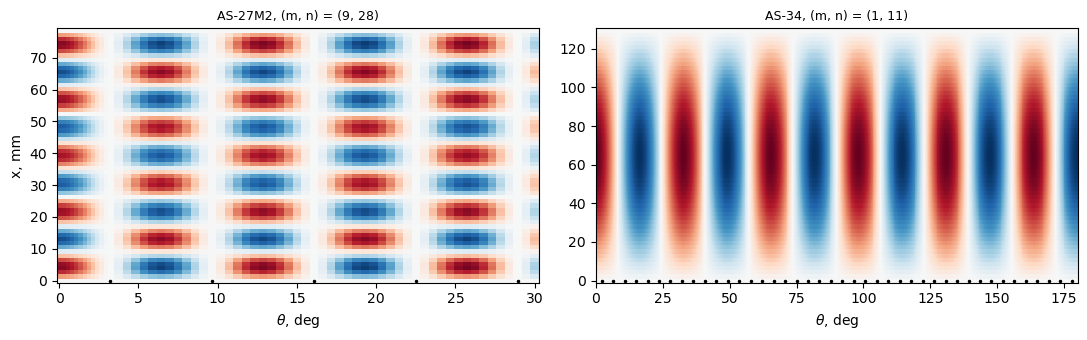

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, s, frac in ((axes[0], 'AS-27M2', 1/6), (axes[1], 'AS-34', 1.)):
    N, modes, N1, md_, skin = RES[(s, 'matched')][:5]
    plot_mode(ax, md_, modes[0][3], skin, shells[s]['R'],
              '%s, (m, n) = (%d, %d)' % (s, *modes[0][1:3]), shells[s]['ns'], frac)
axes[0].set_ylabel('x, mm')
plt.tight_layout()
plt.show()

## Case C of Poorveis and Kabir: external pressure (shell DUD-8 of [5])

Case C of [2] (Table 1, p. 119: 84 outside stringers, $L = 200$ mm, $R =
120.27$ mm, $h = 0.249$ mm, $A_1/(b_1 h) = 0.666$, $e_1/h = 4.030$, $I_1/(b
h^3) = 2.770$, $G_1 J_1/(bD) = 7.505$) is the shell DUD-8 of Abramovich,
Weller and Singer [5] (Table 1, p. 2: $h = 0.249$ mm, $L = 200$ mm, $R/h =
483$, $b_1/h = 36.15$, $A_1/(b_1 h) = 0.666$, $I_1/(b_1 h^3) = 2.77$, $e_1/h
= -4.03$, 84 integral external stringers, 7075-T6, $E = 7.5 \times 10^4$
MPa, $\nu = 0.3$; the footnote also prints $R = 120.12$ mm and $b_1 = 8.985$
mm, whereas $R/h$ and $b_1/h$ give 120.27 mm and 9.00 mm, the values of [2]
used here; $G_1 J_1/(bD)$ is from [2]). Nominal simple supports, found
between SS-3 and SS-4 by the vibration correlation technique (p. 3, p. 8).
Table 4 of [5] (p. 9), DUD-8, with the predictions of [5]:

| run | load | test $(n/m)$ | SS3 $(n/m)$ | SS4 $(n/m)$ | equivalent springs $(n/m)$ |
|---|---|---|---|---|---|
| 1 | external pressure, kPa | 13.55 (10/1) | 13.3 (11/1) | 16.7 (13/1) | 14.6 (11/1) |
| 2 | pressure, kPa, at $P = 4$ kN | 12.3 (9/1) | 12.0 (11/1) | 15.8 (13/1) | 14.2 (12/1) |
| 3 | pressure, kPa, at $P = 8$ kN | 11.10 (9/1) | 10.7 (11/1) | 14.8 (12/1) | 13.3 (12/1) |
| 4 | axial compression, kN | 32 (7/1) | 33.14 (9/1) | 54.05 (10/1) | 41.80 (10/1) |

Table 2 of [2] (p. 119) lists runs 1 and 3 as C1 and C2: test 0.001355 and
0.001110 kg/mm$^2$ (the latter at $P = 1.0587$ kg/mm), smeared (nonlinear)
0.001316 (10, 11) and 0.001095 (10, 11), discrete (nonlinear) 0.001480
(10, 11, 10) and 0.001270 (10, 10, 10), with $(M, n)$ or $(M, n, N)$, $M$
and $N$ the numbers of Ritz terms of [2].

**Units.** [2] converts with 1 kg = 10 N: 13.55 kPa = 0.001355 kg/mm$^2$,
$P = 8000/(2\pi \times 120.27)/10 = 1.0587$ kg/mm, $E = 7500$ kg/mm$^2$ = 75
GPa of [5]. The model uses these units (mm, $E = 7500$); $10^4 q$ is the
pressure in kPa, printed in the tables.

**Lateral or hydrostatic pressure.** [2] writes the external work of a radial
dead pressure $q_D$, adds that "for hydrostatic pressure, $P$ is related to
$q_D$ ($P = R q_D/2$)" and gives the load stiffness of a live pressure (p.
117), without saying which applies to case C. [5] says only "external
pressure"; its Fig. 1 (p. 3) draws the pressure on the shell wall and on the
bottom end plate inside the pressure vessel (closed ends, the end load of
hydrostatic pressure); whether the load-cell value $P$ includes this end load
is not said. Both are computed, first
as dead loads (a live variant follows the results): **lateral** ($\bar{N}_y = q
R$, $\bar{N}_x = 0$) and **hydrostatic** ($\bar{N}_x = q R/2$ in addition);
$P$ of runs 2 and 3 is added to $\bar{N}_x$.

**Smeared theory.** Equation (15) of [4] (p. 12) holds for any combination
of $\bar{N}_x$ and $\bar{N}_y$ (positive in compression, p. 8), "under
hydrostatic or lateral pressure" included: $(m\pi/L)^2 \bar{N}_x +
(n/R)^2 \bar{N}_y$ equals the right-hand side of `su.smeared_ss`; with
$\bar{N}_y = q R$ and $\bar{N}_x = P/(2\pi R) + \kappa q R/2$ ($\kappa = 0$
lateral, 1 hydrostatic) it gives $q$ (`su.smeared_ss_pressure`).

**Discrete model** (`su.buckling_pressure`): the assembly and SS3 ends of the
axial cases; the membrane pre-buckling state of equation (15): `Nyy` $= -q
R$ in the skin panels, no hoop force in the blades, and for the hydrostatic
end load the uniform axial strain of skin and blades of
`su.buckling_membrane`. The fixed load $P$ enters through the attributes
`Nxx_cte` of the panels, added to the constitutive stiffness, so that the
eigenvalue is the pressure. The membrane state is chosen, rather than a
linear static state from a pressure load, because it is the state of
equation (15): the comparison with the smeared theory is like for like, as
in the axial cases; a static state would add the bending of the skin at the
SS3 ends ($w = 0$ holds back the radial contraction), which [2] includes
with the nonlinear pre-buckling deformation.

In [7]:
# Poorveis and Kabir (2006), Table 1 (p. 119) = DUD-8, Table 1 of [5] (p. 2)
POORVEIS_C = (200.00, 120.27, 0.249, 84, 0.666, 4.030, 2.770, 7.505)
KPA = 1e4  # kPa per unit pressure of the model (1 kg = 10 N, mm)
# Table 4 of [5], p. 9 (kPa): P (kN), test, SS3, SS4, equivalent springs
DUD8 = {1: (0., 13.55, 13.3, 16.7, 14.6), 2: (4., 12.3, 12.0, 15.8, 14.2),
        3: (8., 11.10, 10.7, 14.8, 13.3)}
DUD8_AXIAL = (32., 33.14, 54.05, 41.80)  # kN, run 4
# Table 2 of [2], p. 119 (units of the model): test, smeared (nonlinear), discrete (nonlinear)
POORVEIS_CT2 = {1: (0.001355, 0.001316, 0.001480), 3: (0.001110, 0.001095, 0.001270)}
L, R, h, ns, Ab, e, Ib, eta = POORVEIS_C
b = 2*np.pi*R/ns
dc = shell(h, R, L, ns, Ab*b*h, Ib*b*h**3, e*h, eta*b*E*h**3/(12*(1 - NU**2))/G)
shells['C'] = dc
kN = 2*np.pi*R*10/1e3  # kN per unit axial force per unit circumference
LOADS = [(run, load, hyd, DUD8[run][0]/kN) for run in DUD8
         for load, hyd in (('lateral', False), ('hydrostatic', True))]
print('case C: b = %.3f mm, t_s = %.3f mm, h_s = %.3f mm, (h + h_s)/2 = %.4f mm (e_1 = %.4f mm), '
      'I_t1 = %.4f mm^4, I_t1/J_plate = %.3f; P = 8 kN: %.4f kg/mm'
      % (b, dc['ts'], dc['hs'], (h + dc['hs'])/2, dc['e'], dc['J'], dc['J']/dc['Jplate'], 8/kN))
Wsec = (dc['A'], dc['e'], dc['I'] + dc['A']*dc['e']**2)
Psec = (dc['ts']*dc['Hs'], dc['Hs']/2, dc['ts']*dc['Hs']**3/3)
args = (dc['R'], dc['L'], dc['h'], E, NU, dc['b'])
smC = {}
rows = []
for run, load, hyd, P in LOADS:
    s = {'W': su.smeared_ss_pressure(*args, *Wsec, dc['J'], hyd, P),
         'matched': su.smeared_ss_pressure(*args, *Psec, dc['J'], hyd, P),
         'plate': su.smeared_ss_pressure(*args, *Psec, dc['Jplate'], hyd, P)}
    smC[(run, load)] = s
    P_kN, test, ss3 = DUD8[run][:3]
    qW = KPA*s['W'][0]
    rows.append([run, P_kN, load, '%.2f %s' % (qW, s['W'][1]),
                 '%.2f %s' % (KPA*s['matched'][0], s['matched'][1]), '%.2f' % (KPA*s['plate'][0]),
                 ss3, '%+.1f %%' % pct(qW, ss3), test, '%+.1f %%' % pct(qW, test)])
table(['run', 'P, kN', 'pressure', 'Eq. (15), section of [2], kPa (m, n)', 'Eq. (15), strip, matched J',
       'Eq. (15), strip, plate J', 'SS3 of [5]', 'section of [2] vs SS3 of [5]', 'test [5]',
       'section of [2] vs test'], rows)
sma = {'W': su.smeared_ss(*args, *Wsec, dc['J']), 'matched': su.smeared_ss(*args, *Psec, dc['J']),
       'plate': su.smeared_ss(*args, *Psec, dc['Jplate'])}
print('run 4, axial compression, Eq. (15): section of [2] %.2f kN %s (SS3 of [5] %.2f kN, %+.1f %%; test %.0f kN), '
      'strip matched J %.2f kN, plate J %.2f kN'
      % (kN*sma['W'][0], sma['W'][1], DUD8_AXIAL[1], pct(kN*sma['W'][0], DUD8_AXIAL[1]), DUD8_AXIAL[0],
         kN*sma['matched'][0], kN*sma['plate'][0]))

case C: b = 8.996 mm, t_s = 0.848 mm, h_s = 1.759 mm, (h + h_s)/2 = 1.0041 mm (e_1 = 1.0035 mm), I_t1 = 0.2482 mm^4, I_t1/J_plate = 0.648; P = 8 kN: 1.0587 kg/mm


| run | P, kN | pressure | Eq. (15), section of [2], kPa (m, n) | Eq. (15), strip, matched J | Eq. (15), strip, plate J | SS3 of [5] | section of [2] vs SS3 of [5] | test [5] | section of [2] vs test |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | 13.38 (1, 11) | 13.42 (1, 11) | 14.31 | 13.3 | +0.6 % | 13.55 | -1.3 % |
| 1 | 0.0 | hydrostatic | 13.18 (1, 11) | 13.23 (1, 11) | 14.10 | 13.3 | -0.9 % | 13.55 | -2.7 % |
| 2 | 4.0 | lateral | 12.08 (1, 11) | 12.12 (1, 11) | 13.01 | 12.0 | +0.7 % | 12.3 | -1.8 % |
| 2 | 4.0 | hydrostatic | 11.90 (1, 11) | 11.95 (1, 11) | 12.82 | 12.0 | -0.8 % | 12.3 | -3.2 % |
| 3 | 8.0 | lateral | 10.78 (1, 11) | 10.83 (1, 11) | 11.71 | 10.7 | +0.8 % | 11.1 | -2.9 % |
| 3 | 8.0 | hydrostatic | 10.62 (1, 11) | 10.67 (1, 11) | 11.54 | 10.7 | -0.7 % | 11.1 | -4.3 % |

run 4, axial compression, Eq. (15): section of [2] 34.04 kN (1, 9) (SS3 of [5] 33.14 kN, +2.7 %; test 32 kN), strip matched J 34.30 kN, plate J 36.13 kN


**Convergence** (matched $J$, the six pressure loadings).

In [8]:
LEVELS_C = [(12, 6, 4), (16, 8, 4), (20, 10, 5), (24, 10, 5)]
t0 = time.time()
RESC = {}
rows = []
for run, load, hyd, P in LOADS:
    prev = None
    for lev in LEVELS_C:
        RESC[(lev, 'matched', run, load)] = su.buckling_pressure(
            dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', dc['ns'], *lev,
            D66_factor=dc['J']/dc['Jplate'], hydrostatic=hyd, Nx0=P)
        q, modes, md_, skin, ndof, dt = RESC[(lev, 'matched', run, load)]
        rows.append([run, load, lev, ndof, '%.1f' % dt, '%.3f' % (KPA*q), '(%d, %d)' % modes[0][1:3],
                     '' if prev is None else '%+.2f %%' % pct(q, prev)])
        prev = q
table(['run', 'pressure', 'm_x, n_y, n_b', 'dofs', 'time, s', 'q_cr, kPa', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| run | pressure | m_x, n_y, n_b | dofs | time, s | q_cr, kPa | (m, n) | change |
|---|---|---|---|---|---|---|---|
| 1 | lateral | (12, 6, 4) | 11495 | 7.1 | 13.439 | (1, 11) |  |
| 1 | lateral | (16, 8, 4) | 19151 | 15.4 | 13.427 | (1, 11) | -0.09 % |
| 1 | lateral | (20, 10, 5) | 31415 | 26.2 | 13.415 | (1, 11) | -0.08 % |
| 1 | lateral | (24, 10, 5) | 37631 | 36.3 | 13.407 | (1, 11) | -0.06 % |
| 1 | hydrostatic | (12, 6, 4) | 11495 | 6.9 | 13.240 | (1, 11) |  |
| 1 | hydrostatic | (16, 8, 4) | 19151 | 15.7 | 13.228 | (1, 11) | -0.09 % |
| 1 | hydrostatic | (20, 10, 5) | 31415 | 26.5 | 13.217 | (1, 11) | -0.08 % |
| 1 | hydrostatic | (24, 10, 5) | 37631 | 36.2 | 13.209 | (1, 11) | -0.06 % |
| 2 | lateral | (12, 6, 4) | 11495 | 7.0 | 12.117 | (1, 11) |  |
| 2 | lateral | (16, 8, 4) | 19151 | 15.1 | 12.105 | (1, 11) | -0.10 % |
| 2 | lateral | (20, 10, 5) | 31415 | 26.8 | 12.093 | (1, 11) | -0.09 % |
| 2 | lateral | (24, 10, 5) | 37631 | 36.8 | 12.085 | (1, 11) | -0.07 % |
| 2 | hydrostatic | (12, 6, 4) | 11495 | 7.2 | 11.938 | (1, 11) |  |
| 2 | hydrostatic | (16, 8, 4) | 19151 | 14.6 | 11.926 | (1, 11) | -0.10 % |
| 2 | hydrostatic | (20, 10, 5) | 31415 | 26.8 | 11.914 | (1, 11) | -0.09 % |
| 2 | hydrostatic | (24, 10, 5) | 37631 | 36.2 | 11.906 | (1, 11) | -0.07 % |
| 3 | lateral | (12, 6, 4) | 11495 | 6.7 | 10.795 | (1, 11) |  |
| 3 | lateral | (16, 8, 4) | 19151 | 15.1 | 10.783 | (1, 11) | -0.12 % |
| 3 | lateral | (20, 10, 5) | 31415 | 29.2 | 10.771 | (1, 11) | -0.10 % |
| 3 | lateral | (24, 10, 5) | 37631 | 38.8 | 10.763 | (1, 11) | -0.08 % |
| 3 | hydrostatic | (12, 6, 4) | 11495 | 6.9 | 10.636 | (1, 11) |  |
| 3 | hydrostatic | (16, 8, 4) | 19151 | 14.5 | 10.623 | (1, 11) | -0.12 % |
| 3 | hydrostatic | (20, 10, 5) | 31415 | 26.9 | 10.612 | (1, 11) | -0.10 % |
| 3 | hydrostatic | (24, 10, 5) | 37631 | 37.2 | 10.604 | (1, 11) | -0.08 % |

516 s


**Results** (finest level; plate $J$ as well; run 4 with
`su.buckling_membrane`). "Gap": discrete model against equation (15) for the
same strip and twisting stiffness. Pressures in kPa.

294 s


| run | P, kN | pressure | J | discrete q (m, n) | Eq. (15), same strip | gap | test [5] | vs test | SS3 of [5] | vs SS3 of [5] | smeared [2] | vs smeared [2] | discrete [2] | vs discrete [2] |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | matched | 13.41 (1, 11) | 13.42 | **-0.1 %** | 13.55 | -1.1 % | 13.3 | +0.8 % | 13.16 | +1.9 % | 14.80 | -9.4 % |
| 1 | 0.0 | lateral | plate | 14.21 (1, 11) | 14.31 | **-0.7 %** | 13.55 | +4.9 % | 13.3 | +6.8 % | 13.16 | +8.0 % | 14.80 | -4.0 % |
| 1 | 0.0 | hydrostatic | matched | 13.21 (1, 11) | 13.23 | **-0.1 %** | 13.55 | -2.5 % | 13.3 | -0.7 % | 13.16 | +0.4 % | 14.80 | -10.8 % |
| 1 | 0.0 | hydrostatic | plate | 14.00 (1, 11) | 14.10 | **-0.7 %** | 13.55 | +3.3 % | 13.3 | +5.3 % | 13.16 | +6.4 % | 14.80 | -5.4 % |
| 2 | 4.0 | lateral | matched | 12.09 (1, 11) | 12.12 | **-0.3 %** | 12.3 | -1.7 % | 12.0 | +0.7 % | - | - | - | - |
| 2 | 4.0 | lateral | plate | 12.89 (1, 11) | 13.01 | **-1.0 %** | 12.3 | +4.8 % | 12.0 | +7.4 % | - | - | - | - |
| 2 | 4.0 | hydrostatic | matched | 11.91 (1, 11) | 11.95 | **-0.4 %** | 12.3 | -3.2 % | 12.0 | -0.8 % | - | - | - | - |
| 2 | 4.0 | hydrostatic | plate | 12.70 (1, 11) | 12.82 | **-1.0 %** | 12.3 | +3.2 % | 12.0 | +5.8 % | - | - | - | - |
| 3 | 8.0 | lateral | matched | 10.76 (1, 11) | 10.83 | **-0.6 %** | 11.1 | -3.0 % | 10.7 | +0.6 % | 10.95 | -1.7 % | 12.70 | -15.3 % |
| 3 | 8.0 | lateral | plate | 11.56 (1, 11) | 11.71 | **-1.3 %** | 11.1 | +4.2 % | 10.7 | +8.1 % | 10.95 | +5.6 % | 12.70 | -8.9 % |
| 3 | 8.0 | hydrostatic | matched | 10.60 (1, 11) | 10.67 | **-0.6 %** | 11.1 | -4.5 % | 10.7 | -0.9 % | 10.95 | -3.2 % | 12.70 | -16.5 % |
| 3 | 8.0 | hydrostatic | plate | 11.39 (1, 11) | 11.54 | **-1.3 %** | 11.1 | +2.6 % | 10.7 | +6.5 % | 10.95 | +4.0 % | 12.70 | -10.3 % |

| run 4, J | discrete P, kN (m, n) | Eq. (15), same strip | gap | test [5] | vs test | SS3 of [5] | vs SS3 of [5] |
|---|---|---|---|---|---|---|---|
| matched | 33.69 (1, 9) | 34.30 | **-1.8 %** | 32.0 | +5.3 % | 33.14 | +1.6 % |
| plate | 35.29 (1, 9) | 36.13 | **-2.3 %** | 32.0 | +10.3 % | 33.14 | +6.5 % |

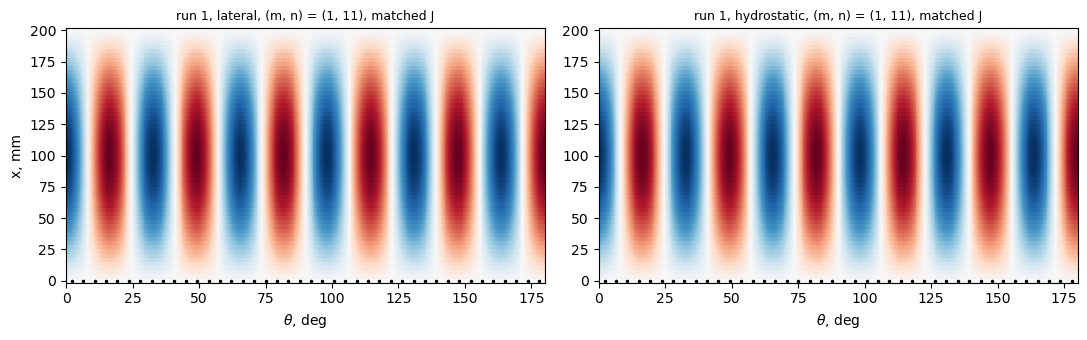

In [9]:
lev = LEVELS_C[-1]
t0 = time.time()
for run, load, hyd, P in LOADS:
    RESC[(lev, 'plate', run, load)] = su.buckling_pressure(
        dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', dc['ns'], *lev,
        hydrostatic=hyd, Nx0=P)
axC = {J: su.buckling_membrane(dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', 'SS',
                               dc['ns'], *lev, D66_factor=dc['J']/dc['Jplate'] if J == 'matched' else 1.)
       for J in ('matched', 'plate')}
print('%.0f s' % (time.time() - t0))
rows = []
for run, load, hyd, P in LOADS:
    P_kN, test, ss3, ss4, sp = DUD8[run]
    for J in ('matched', 'plate'):
        q, modes = RESC[(lev, J, run, load)][:2]
        sm = smC[(run, load)][J]
        row = [run, P_kN, load, J, '%.2f (%d, %d)' % (KPA*q, *modes[0][1:3]), '%.2f' % (KPA*sm[0]),
               '**%+.1f %%**' % pct(q, sm[0]), test, '%+.1f %%' % pct(KPA*q, test),
               ss3, '%+.1f %%' % pct(KPA*q, ss3)]
        if run in POORVEIS_CT2:
            t2, sm2, di2 = POORVEIS_CT2[run]
            row += ['%.2f' % (KPA*sm2), '%+.1f %%' % pct(q, sm2), '%.2f' % (KPA*di2), '%+.1f %%' % pct(q, di2)]
        else:
            row += ['-', '-', '-', '-']
        rows.append(row)
table(['run', 'P, kN', 'pressure', 'J', 'discrete q (m, n)', 'Eq. (15), same strip', 'gap', 'test [5]',
       'vs test', 'SS3 of [5]', 'vs SS3 of [5]', 'smeared [2]', 'vs smeared [2]', 'discrete [2]',
       'vs discrete [2]'], rows)
rows = []
for J in ('matched', 'plate'):
    N, modes = axC[J][:2]
    rows.append([J, '%.2f (%d, %d)' % (kN*N, *modes[0][1:3]), '%.2f' % (kN*sma[J][0]),
                 '**%+.1f %%**' % pct(N, sma[J][0]), DUD8_AXIAL[0], '%+.1f %%' % pct(kN*N, DUD8_AXIAL[0]),
                 DUD8_AXIAL[1], '%+.1f %%' % pct(kN*N, DUD8_AXIAL[1])])
table(['run 4, J', 'discrete P, kN (m, n)', 'Eq. (15), same strip', 'gap', 'test [5]', 'vs test',
       'SS3 of [5]', 'vs SS3 of [5]'], rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, load in zip(axes, ('lateral', 'hydrostatic')):
    q, modes, md_, skin = RESC[(lev, 'matched', 1, load)][:4]
    plot_mode(ax, md_, modes[0][3], skin, dc['R'],
              'run 1, %s, (m, n) = (%d, %d), matched J' % (load, *modes[0][1:3]), dc['ns'])
axes[0].set_ylabel('x, mm')
plt.tight_layout()
plt.show()

**Live (follower) pressure.** The pressure of the tests is the pressure of
a fluid, which stays normal to the deformed skin and acts on its deformed
area; [2] gives the load stiffness of this live pressure (p. 117) besides
the external work of the dead one. The live variant adds to the geometric
stiffness of the unit pressure the load stiffness of a unit follower pressure
on every skin panel, `Shell.calc_kCfollower` (first-order area vector, the
pressure on the middle surface of the skin, as the hoop force $q R$),
assembled at the offsets of the panels and reduced with the constraints of the
assembly (`su.follower_stiffness`). The end load of the hydrostatic pressure
acts on the rigid end plates and stays a dead axial load. The load
stiffness is unsymmetric in general, symmetric when every edge of the loaded
surface has $w = 0$ or a zero normal displacement (Hibbitt 1979; Schweizerhof
and Ramm 1984, Table 2): here the ends have $w = 0$, the symmetry planes $v
= 0$ and the skin panels are connected to each other, so its skew part is a
check (printed below). The eigenvalue problem is solved as an unsymmetric
one, `structsolve.lb(K, KG + KF, symmetric=False)`: the shift search of
`scipy.sparse.linalg.eigs` along the positive real axis for the lowest
positive real load multiplier, with a parity check of the number of real
multipliers below it. Finest level, matched $J$; run 1 also at the level
before (convergence).

In [10]:
t0 = time.time()
for run, load, hyd, P in LOADS:
    for lv in (LEVELS_C[-2:] if run == 1 else LEVELS_C[-1:]):
        RESC[(lv, 'live', run, load)] = su.buckling_pressure(
            dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', dc['ns'], *lv,
            D66_factor=dc['J']/dc['Jplate'], hydrostatic=hyd, Nx0=P, follower=True)
print('%.0f s' % (time.time() - t0))
md_, skin = RESC[(lev, 'live', 1, 'lateral')][2:4]
KF = su.follower_stiffness(md_, skin)
print('skew part of the reduced load stiffness, ||KF - KF^T||/||KF|| = %.1e'
      % (np.sqrt(((KF - KF.T).data**2).sum())/np.sqrt((KF.data**2).sum())))
rows = []
for run, load, hyd, P in LOADS:
    P_kN, test, ss3 = DUD8[run][:3]
    qd = RESC[(lev, 'matched', run, load)][0]
    ql, modes = RESC[(lev, 'live', run, load)][:2]
    row = [run, P_kN, load, '%.2f' % (KPA*qd), '%.2f (%d, %d)' % (KPA*ql, *modes[0][1:3]),
           '**%+.2f %%**' % pct(ql, qd), test, '%+.1f %%' % pct(KPA*ql, test), ss3,
           '%+.1f %%' % pct(KPA*ql, ss3)]
    if run in POORVEIS_CT2:
        row += ['%.2f' % (KPA*POORVEIS_CT2[run][2]), '%+.1f %%' % pct(ql, POORVEIS_CT2[run][2])]
    else:
        row += ['-', '-']
    rows.append(row)
table(['run', 'P, kN', 'pressure', 'dead q', 'live q (m, n)', 'live vs dead', 'test [5]', 'live vs test',
       'SS3 of [5]', 'live vs SS3 of [5]', 'discrete [2]', 'live vs discrete [2]'], rows)
rows = []
for load in ('lateral', 'hydrostatic'):
    q1, q2 = (RESC[(lv, 'live', 1, load)][0] for lv in LEVELS_C[-2:])
    rows.append([load, LEVELS_C[-2], '%.3f' % (KPA*q1), LEVELS_C[-1], '%.3f' % (KPA*q2), '%+.2f %%' % pct(q2, q1)])
table(['run 1, live', 'level', 'q, kPa', 'level', 'q, kPa', 'change'], rows)

894 s


skew part of the reduced load stiffness, ||KF - KF^T||/||KF|| = 8.0e-11


| run | P, kN | pressure | dead q | live q (m, n) | live vs dead | test [5] | live vs test | SS3 of [5] | live vs SS3 of [5] | discrete [2] | live vs discrete [2] |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | 13.41 | 13.30 (1, 11) | **-0.79 %** | 13.55 | -1.8 % | 13.3 | +0.0 % | 14.80 | -10.1 % |
| 1 | 0.0 | hydrostatic | 13.21 | 13.11 (1, 11) | **-0.78 %** | 13.55 | -3.3 % | 13.3 | -1.5 % | 14.80 | -11.5 % |
| 2 | 4.0 | lateral | 12.09 | 11.99 (1, 11) | **-0.79 %** | 12.3 | -2.5 % | 12.0 | -0.1 % | - | - |
| 2 | 4.0 | hydrostatic | 11.91 | 11.81 (1, 11) | **-0.78 %** | 12.3 | -4.0 % | 12.0 | -1.6 % | - | - |
| 3 | 8.0 | lateral | 10.76 | 10.68 (1, 11) | **-0.79 %** | 11.1 | -3.8 % | 10.7 | -0.2 % | 12.70 | -15.9 % |
| 3 | 8.0 | hydrostatic | 10.60 | 10.52 (1, 11) | **-0.78 %** | 11.1 | -5.2 % | 10.7 | -1.7 % | 12.70 | -17.2 % |

| run 1, live | level | q, kPa | level | q, kPa | change |
|---|---|---|---|---|---|
| lateral | (20, 10, 5) | 13.309 | (24, 10, 5) | 13.301 | -0.06 % |
| hydrostatic | (20, 10, 5) | 13.113 | (24, 10, 5) | 13.105 | -0.06 % |

**Interaction curve of DUD-8.** Shen, Zhou and Chen [3] (Fig. 3(a), p. 57)
give the interaction curve of DUD-8 under combined hydrostatic pressure and
axial load from their boundary-layer postbuckling theory (simply supported
ends, perfect shell and an imperfection $W^*/t = 0.04$), with the tests of
[5], as $R_x = \lambda_p/\lambda_p^*$ against $R_y = \lambda_q/\lambda_q^*$, the
loads divided by their theoretical values under axial compression alone
and external pressure alone (notation, p. 44), which [3] does not print.
Digitized here (reading precision $\pm 0.01$): perfect shell $R_x = 1.00,
0.92, 0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.23, 0.12, 0$ at $R_y = 0, 0.1,
\ldots, 1.0$; tests $(R_y, R_x) = (0.00, 0.93), (0.83, 0.21), (0.93, 0.10),
(1.01, 0.00)$. The discrete model adds $P = 16$ and 24 kN (dead pressure)
to the runs of [5]; the curves of equation (15) are those of the section
of [2]. Left: absolute values with the tests and the SS3 predictions of [5]
(Table 4); right: each curve divided by its own values under pressure alone
and axial load alone, as [3] does.

151 s


| P, kN | pressure | discrete q, kPa (m, n) | Eq. (15), same strip | gap | R_x = P/P_ax | R_y = q/q(P = 0) |
|---|---|---|---|---|---|---|
| 0.0 | lateral | 13.41 (1, 11) | 13.42 | -0.1 % | 0.000 | 1.000 |
| 4.0 | lateral | 12.09 (1, 11) | 12.12 | -0.3 % | 0.119 | 0.901 |
| 8.0 | lateral | 10.76 (1, 11) | 10.83 | -0.6 % | 0.237 | 0.803 |
| 16.0 | lateral | 7.78 (1, 10) | 7.88 | -1.3 % | 0.475 | 0.580 |
| 24.0 | lateral | 4.57 (1, 10) | 4.74 | -3.6 % | 0.712 | 0.341 |
| 0.0 | hydrostatic | 13.21 (1, 11) | 13.23 | -0.1 % | 0.000 | 1.000 |
| 4.0 | hydrostatic | 11.91 (1, 11) | 11.95 | -0.4 % | 0.119 | 0.901 |
| 8.0 | hydrostatic | 10.60 (1, 11) | 10.67 | -0.6 % | 0.237 | 0.803 |
| 16.0 | hydrostatic | 7.64 (1, 10) | 7.74 | -1.3 % | 0.475 | 0.578 |
| 24.0 | hydrostatic | 4.48 (1, 10) | 4.66 | -3.7 % | 0.712 | 0.340 |

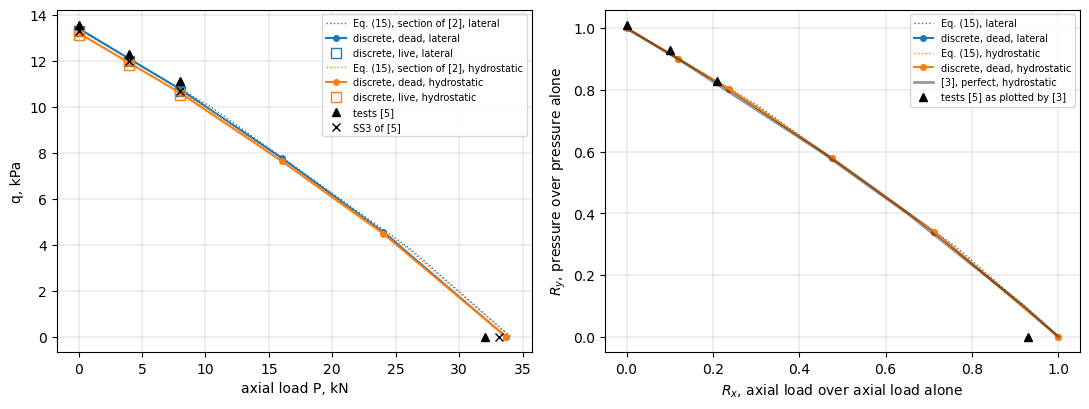

In [11]:
# Shen, Zhou and Chen (1993), Fig. 3(a), p. 57, digitized (+-0.01): perfect shell and tests of [5]
SHEN_F3A_RY = np.linspace(0., 1., 11)
SHEN_F3A_RX = np.array([1.00, 0.92, 0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.23, 0.12, 0.])
SHEN_F3A_TESTS = np.array([(0.00, 0.93), (0.83, 0.21), (0.93, 0.10), (1.01, 0.00)])
P_EXTRA = (16., 24.)  # kN
t0 = time.time()
for P_kN in P_EXTRA:
    for load, hyd in (('lateral', False), ('hydrostatic', True)):
        RESC[(lev, 'matched', 'P%g' % P_kN, load)] = su.buckling_pressure(
            dc['R'], dc['h'], dc['L'], E, NU, dc['ts'], dc['Hs'], 'external', dc['ns'], *lev,
            D66_factor=dc['J']/dc['Jplate'], hydrostatic=hyd, Nx0=P_kN/kN)
print('%.0f s' % (time.time() - t0))
Pax = kN*axC['matched'][0]  # discrete, axial compression alone, kN
rows = []
curves = {}
for load, hyd in (('lateral', False), ('hydrostatic', True)):
    keys = sorted([(run, DUD8[run][0]) for run in DUD8] + [('P%g' % P_kN, P_kN) for P_kN in P_EXTRA],
                  key=lambda k: k[1])
    q0 = RESC[(lev, 'matched', 1, load)][0]
    pts = []
    for key, P_kN in keys:
        q, modes = RESC[(lev, 'matched', key, load)][:2]
        pts.append((P_kN, KPA*q))
        sm = su.smeared_ss_pressure(*args, *Psec, dc['J'], hyd, P_kN/kN)
        rows.append([P_kN, load, '%.2f (%d, %d)' % (KPA*q, *modes[0][1:3]), '%.2f' % (KPA*sm[0]),
                     '%+.1f %%' % pct(q, sm[0]), '%.3f' % (P_kN/Pax), '%.3f' % (q/q0)])
    curves[load] = np.array(pts + [(Pax, 0.)])
table(['P, kN', 'pressure', 'discrete q, kPa (m, n)', 'Eq. (15), same strip', 'gap', 'R_x = P/P_ax',
       'R_y = q/q(P = 0)'], rows)

Ps = np.linspace(0., kN*sma['W'][0], 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for load, hyd, c in (('lateral', False, 'C0'), ('hydrostatic', True, 'C1')):
    qs = np.array([su.smeared_ss_pressure(*args, *Wsec, dc['J'], hyd, P/kN)[0] for P in Ps])
    axes[0].plot(Ps, KPA*qs, c + ':', lw=1, label='Eq. (15), section of [2], %s' % load)
    axes[0].plot(curves[load][:, 0], curves[load][:, 1], c + 'o-', ms=4, label='discrete, dead, %s' % load)
    axes[0].plot([DUD8[r][0] for r in DUD8], [KPA*RESC[(lev, 'live', r, load)][0] for r in DUD8], c + 's',
                 mfc='none', ms=7, label='discrete, live, %s' % load)
    ok = qs > 0
    axes[1].plot(Ps[ok]/Ps[-1], qs[ok]/qs[0], c + ':', lw=1, label='Eq. (15), %s' % load)
    axes[1].plot(curves[load][:, 0]/Pax, curves[load][:, 1]/curves[load][0, 1], c + 'o-', ms=4,
                 label='discrete, dead, %s' % load)
axes[0].plot([DUD8[r][0] for r in DUD8] + [DUD8_AXIAL[0]], [DUD8[r][1] for r in DUD8] + [0.], 'k^',
             label='tests [5]')
axes[0].plot([DUD8[r][0] for r in DUD8] + [DUD8_AXIAL[1]], [DUD8[r][2] for r in DUD8] + [0.], 'kx',
             label='SS3 of [5]')
axes[0].set_xlabel('axial load P, kN')
axes[0].set_ylabel('q, kPa')
axes[1].plot(SHEN_F3A_RX, SHEN_F3A_RY, 'k-', lw=2, alpha=0.4, label='[3], perfect, hydrostatic')
axes[1].plot(SHEN_F3A_TESTS[:, 1], SHEN_F3A_TESTS[:, 0], 'k^', label='tests [5] as plotted by [3]')
axes[1].set_xlabel('$R_x$, axial load over axial load alone')
axes[1].set_ylabel('$R_y$, pressure over pressure alone')
for ax in axes:
    ax.grid(True, lw=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## Case D of Poorveis and Kabir: combined external pressure and axial compression

Case D of [2] (Table 1, p. 119: $L = 130$ mm, $R = 120.10$ mm, $h = 0.254$
mm, 85 outside stringers, $A_1/(b_1 h) = 0.590$, $e_1/h = 3.420$,
$I_1/(bh^3) = 1.680$, $G_1 J_1/(bD) = 6.563$) is the last shell of Table 1 of
Shen, Zhou and Chen [3] (p. 56: $L$, $R$, $t$, $n_s$, $A_1/(d_1 t) = 0.59$,
$-e_1/t = 3.42$, $I_1/(d_1 t^3) = 1.68$, $G_1 J_1/(d_1 D) = 6.5632$, $E = 7500$
kg/mm$^2$, $\nu = 0.3$), whose test is from Singer and Abramovich (1979, AIAA
J. 17, 762-769, cited through [3]; ends "close to clamped", [3], p. 55).
[3] gives for this shell, in axial compression only:

| quantity | value, kg | $\bar{N}$, kg/mm | source |
|---|---|---|---|
| test $P_{exp}$ (1, 9) | 4025 | 5.334 | Singer and Abramovich, through [3], Table 1 |
| lowest postbuckling load of the test $P_{post}$ | 2250 | 2.982 | same |
| ratio printed under SS3 / C4 | 1.09 / 0.62 | | same |
| perfect shell, boundary-layer theory, $P_{cr}$ (1, 10) | 3918 | 5.192 | [3], Table 1 |
| lowest postbuckling load $P_{low}$ | 2783 | 3.688 | [3], Table 1 |

($\bar{N} = P/(2\pi R)$; 4025 kg is the test 5.334 kg/mm of [2], Table 2.)
The header of the ratio columns is printed "$P_{exp}/P_{post}$", but
$4025/2250 = 1.79$; the printed 1.09 and 0.62 are consistent with the test
divided by an SS3 and a C4 (clamped) prediction of Singer and Abramovich
(4025/1.09 = 3693 kg, 4025/0.62 = 6492 kg), not printed in [3]; these two
values are shown as such derived values. Neither [2] nor [3] gives a
combined-loading or pressure value for this shell: the interaction curves of
[3] (Fig. 3) are those of DUD-8 (case C, previous section) and DUD-10. The
interaction curve of case D is computed here as for case C: equation (15)
for the strip and the section of [2], and the discrete model (whole cylinder,
85 stringers, finest level, matched $J$) under the pressure $q$ at fixed
axial loads $P = 0$, 1000, 2000 and 3000 kg, lateral and hydrostatic, dead
and live. The loads are in kg (kilogram-force) as in [3]; $q$ in
kg/mm$^2$ is printed in kPa, $1$ kg/mm$^2$ = 9806.65 kPa.

2110 s


| case D, lateral, P = 0: level | dofs | pressure | q_cr, kPa (m, n) | change |
|---|---|---|---|---|
| (12, 6, 4) | 23119 | dead | 23.221 (1, 14) |  |
| (16, 8, 4) | 38759 | dead | 23.184 (1, 14) | -0.16 % |
| (20, 10, 5) | 63579 | dead | 23.154 (1, 14) | -0.13 % |
| (16, 8, 4) |  | live | 23.072 |  |
| (20, 10, 5) |  | live | 23.042 | -0.13 % |

| P, kg | pressure | Eq. (15), section of [2], kPa (m, n) | Eq. (15), strip, matched J | discrete, dead (m, n) | gap | discrete, live (m, n) | live vs dead |
|---|---|---|---|---|---|---|---|
| 0 | lateral | 23.28 (1, 14) | 23.34 | 23.15 (1, 14) | **-0.8 %** | 23.04 (1, 14) | -0.48 % |
| 0 | hydrostatic | 22.79 (1, 14) | 22.85 | 22.66 (1, 14) | **-0.8 %** | 22.55 (1, 14) | -0.47 % |
| 1000 | lateral | 18.21 (1, 13) | 18.29 | 18.06 (1, 13) | **-1.3 %** | 17.96 (1, 13) | -0.56 % |
| 1000 | hydrostatic | 17.76 (1, 13) | 17.85 | 17.61 (1, 13) | **-1.3 %** | 17.52 (1, 13) | -0.54 % |
| 2000 | lateral | 12.44 (1, 12) | 12.57 | 12.25 (1, 12) | **-2.5 %** | 12.17 (1, 12) | -0.65 % |
| 2000 | hydrostatic | 12.08 (1, 12) | 12.21 | 11.90 (1, 12) | **-2.5 %** | 11.82 (1, 12) | -0.63 % |
| 3000 | lateral | 5.93 (1, 11) | 6.12 | 5.68 (1, 11) | **-7.1 %** | 5.64 (1, 11) | -0.76 % |
| 3000 | hydrostatic | 5.73 (1, 11) | 5.91 | 5.49 (1, 11) | **-7.2 %** | 5.45 (1, 11) | -0.73 % |

| axial compression alone | P, kg | discrete (3741 kg) vs |
|---|---|---|
| test (Singer and Abramovich, through [3]) | 4025 | -7.1 % |
| SS3 prediction, 4025/1.09 (derived) | 3693 | +1.3 % |
| C4 prediction, 4025/0.62 (derived) | 6492 | -42.4 % |
| perfect shell, [3] | 3918 | -4.5 % |
| smeared, nonlinear, [2] | 4052 | -7.7 % |
| discrete, nonlinear, [2] | 4113 | -9.0 % |
| Eq. (15), section of [2] | 3787 | -1.2 % |
| Eq. (15), strip, matched J | 3813 | -1.9 % |

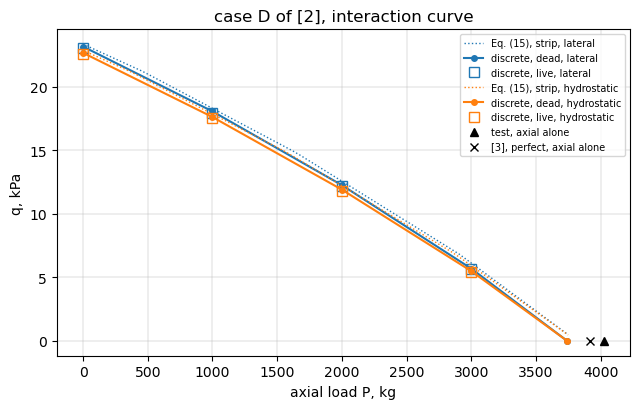

In [12]:
# Shen, Zhou and Chen (1993), Table 1 (p. 56), last row (= case D of [2]), kg
SHEN_D = dict(P_exp=4025., P_post=2250., r_ss3=1.09, r_c4=0.62, P_cr=3918., P_low=2783.)
KPA_D = KGF*1e3  # kPa per kg/mm^2
dd = shells['D']
kgD = 2*np.pi*dd['R']  # kg per unit axial force per unit circumference
PD = (0., 1000., 2000., 3000.)  # kg
argsD = (dd['R'], dd['L'], dd['h'], E, NU, dd['b'])
WsecD = (dd['A'], dd['e'], dd['I'] + dd['A']*dd['e']**2)
PsecD = (dd['ts']*dd['Hs'], dd['Hs']/2, dd['ts']*dd['Hs']**3/3)
levD = LEVELS[-1]
t0 = time.time()
RESD = {}
for lv in LEVELS:
    RESD[(lv, 'dead', 0., 'lateral')] = su.buckling_pressure(
        dd['R'], dd['h'], dd['L'], E, NU, dd['ts'], dd['Hs'], 'external', dd['ns'], *lv,
        D66_factor=dd['J']/dd['Jplate'])
for P in PD:
    for load, hyd in (('lateral', False), ('hydrostatic', True)):
        for kind in ('dead', 'live'):
            if (levD, kind, P, load) not in RESD:
                RESD[(levD, kind, P, load)] = su.buckling_pressure(
                    dd['R'], dd['h'], dd['L'], E, NU, dd['ts'], dd['Hs'], 'external', dd['ns'], *levD,
                    D66_factor=dd['J']/dd['Jplate'], hydrostatic=hyd, Nx0=P/kgD, follower=(kind == 'live'))
RESD[(LEVELS[-2], 'live', 0., 'lateral')] = su.buckling_pressure(
    dd['R'], dd['h'], dd['L'], E, NU, dd['ts'], dd['Hs'], 'external', dd['ns'], *LEVELS[-2],
    D66_factor=dd['J']/dd['Jplate'], follower=True)
print('%.0f s' % (time.time() - t0))
rows = []
prev = None
for lv in LEVELS:
    q, modes, md_, skin, ndof = RESD[(lv, 'dead', 0., 'lateral')][:5]
    rows.append([lv, ndof, 'dead', '%.3f (%d, %d)' % (KPA_D*q, *modes[0][1:3]),
                 '' if prev is None else '%+.2f %%' % pct(q, prev)])
    prev = q
q1, q2 = RESD[(LEVELS[-2], 'live', 0., 'lateral')][0], RESD[(levD, 'live', 0., 'lateral')][0]
rows.append([LEVELS[-2], '', 'live', '%.3f' % (KPA_D*q1), ''])
rows.append([levD, '', 'live', '%.3f' % (KPA_D*q2), '%+.2f %%' % pct(q2, q1)])
table(['case D, lateral, P = 0: level', 'dofs', 'pressure', 'q_cr, kPa (m, n)', 'change'], rows)

rows = []
for P in PD:
    for load, hyd in (('lateral', False), ('hydrostatic', True)):
        smS = su.smeared_ss_pressure(*argsD, *PsecD, dd['J'], hyd, P/kgD)
        smW = su.smeared_ss_pressure(*argsD, *WsecD, dd['J'], hyd, P/kgD)
        qd, md_ = RESD[(levD, 'dead', P, load)][:2]
        ql, ml = RESD[(levD, 'live', P, load)][:2]
        rows.append(['%.0f' % P, load, '%.2f %s' % (KPA_D*smW[0], smW[1]), '%.2f' % (KPA_D*smS[0]),
                     '%.2f (%d, %d)' % (KPA_D*qd, *md_[0][1:3]), '**%+.1f %%**' % pct(qd, smS[0]),
                     '%.2f (%d, %d)' % (KPA_D*ql, *ml[0][1:3]), '%+.2f %%' % pct(ql, qd)])
table(['P, kg', 'pressure', 'Eq. (15), section of [2], kPa (m, n)', 'Eq. (15), strip, matched J',
       'discrete, dead (m, n)', 'gap', 'discrete, live (m, n)', 'live vs dead'], rows)

Nd = RES[('D', 'matched')][0]
ax_refs = [('test (Singer and Abramovich, through [3])', SHEN_D['P_exp']),
           ('SS3 prediction, 4025/1.09 (derived)', SHEN_D['P_exp']/SHEN_D['r_ss3']),
           ('C4 prediction, 4025/0.62 (derived)', SHEN_D['P_exp']/SHEN_D['r_c4']),
           ('perfect shell, [3]', SHEN_D['P_cr']),
           ('smeared, nonlinear, [2]', kgD*POORVEIS_T2['D'][1]),
           ('discrete, nonlinear, [2]', kgD*POORVEIS_T2['D'][2]),
           ('Eq. (15), section of [2]', kgD*shells['D']['sm_W'][0]),
           ('Eq. (15), strip, matched J', kgD*shells['D']['sm']['matched'][0])]
table(['axial compression alone', 'P, kg', 'discrete (%.0f kg) vs' % (kgD*Nd)],
      [[name, '%.0f' % P, '%+.1f %%' % pct(kgD*Nd, P)] for name, P in ax_refs])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
Ps = np.linspace(0., kgD*shells['D']['sm']['matched'][0], 60)
for load, hyd, c in (('lateral', False, 'C0'), ('hydrostatic', True, 'C1')):
    qs = np.array([su.smeared_ss_pressure(*argsD, *PsecD, dd['J'], hyd, P/kgD)[0] for P in Ps])
    ok = qs > 0
    ax.plot(Ps[ok], KPA_D*qs[ok], c + ':', lw=1, label='Eq. (15), strip, %s' % load)
    ax.plot(list(PD) + [kgD*Nd], [KPA_D*RESD[(levD, 'dead', P, load)][0] for P in PD] + [0.], c + 'o-', ms=4,
            label='discrete, dead, %s' % load)
    ax.plot(PD, [KPA_D*RESD[(levD, 'live', P, load)][0] for P in PD], c + 's', mfc='none', ms=7,
            label='discrete, live, %s' % load)
ax.plot([SHEN_D['P_exp']], [0.], 'k^', label='test, axial alone')
ax.plot([SHEN_D['P_cr']], [0.], 'kx', label='[3], perfect, axial alone')
ax.set_xlabel('axial load P, kg')
ax.set_ylabel('q, kPa')
ax.set_title('case D of [2], interaction curve')
ax.grid(True, lw=0.3)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Case B** of [2] is cylinder 1 of Card and Jones (1966),
`card1966_blade_cylinder_buckling.ipynb`; case C is in the previous
section.

## Discussion

- **Input.** Equation (15) of [4] with the stringer properties of Table 1 of
  [1] reproduces the SS3 loads of [1] within 0.14 % for the five shells, so
  the section, the material and the number of stringers are read as Weller
  and Singer read them. The stringers are rectangles; their torsion constant
  $I_{t1}$ is that of the rectangle.
- **General instability (AS-34, AS-35, case D; $\theta = 0.47$, $b/\sqrt{Rh}
  = 1.6$).** The discrete model buckles in the general mode $(m, n) = (1,
  11)$ of the smeared theory, 1.7 % below equation (15) for the same
  plate strip with the matched twisting stiffness (3.2 to 3.3 % with the
  plate twisting stiffness). This is the discreteness gap at this spacing: one
  to two percent. Against the SS3 loads of [1] (for the rectangle) the
  discrete model is 1.1 % below; the overlap of the strip with the skin and its
  centroid at $H_s/2$ instead of $e_1$ make equation (15) for the strip 0.8 %
  higher than for the rectangle. The tests are at 82 and 84 % of SS3
  (the "linearity" of [1]), +18 and +21 % from the discrete model: the
  difference between test and theory is the imperfection sensitivity
  discussed in [1], not the discreteness of the stringers.
- **Panel instability (AS-27; $\theta = 0.79$ to 0.81).** The lowest mode of
  the discrete model is local: the skin between the stringers buckles with
  one half-wave per bay ($n = n_s/2 = 28$) and nine axial half-waves, at
  4.13 to 4.54 kg/mm, 18.6 to 25.6 % below the general instability of the smeared
  theory, which cannot represent this mode. This is the case of a large
  "gap" in the literature: Poorveis and Kabir found their discrete value 30 %
  below their smeared one for AS-27M2 and attributed it to panel instability
  ([2], p. 119). The discrete model of this notebook is +4.1 % from the
  test of AS-27M2 and +6.7 % from the discrete value of [2] (whose model
  includes the nonlinear pre-buckling deformation and transverse shear); the
  three tests of the nearly equal AS-27 shells scatter from 4.36 to 5.17
  kg/mm, and the model is -13.1, +4.1 and -14.0 % from them. The local load is almost
  independent of the twisting stiffness of the stringers (+0.9 to +1.1 % from
  matched to plate $J$), whereas the general-instability load of the smeared
  theory rises by 44 % with the plate twisting stiffness: with an unmatched
  plate strip the apparent gap would be 43 to 48 %. In the model the skin
  bay is the whole pitch $b = 13.5$ mm, the stringer root being a line; the
  real stringers are 1.53 mm wide (11 % of the pitch), which leaves a
  narrower skin panel and would raise the local load (a plate-buckling load
  scales with the inverse square of the panel width: $(13.53/12.0)^2 = 1.27$
  for the free width, an estimate, not a computed value).
- **Case D of [2]** (85 stringers, from Shen, Zhou and Chen [3]): discrete
  4.957 kg/mm, -1.9 % from equation (15) for the same strip, -7.1 %
  from the test of [3] cited by [2]. Poorveis and Kabir give the discrete
  value 1.5 % *above* the smeared one (5.450 and 5.370 kg/mm); their smeared
  nonlinear value is 7 % above equation (15) with their own section (5.018
  kg/mm), so the difference between their two models and the linear theory
  is larger than the discreteness effect found here. Case B of [2] (cylinder
  1 of Card and Jones, discrete 5.2 % above smeared in [2]): both
  implementations of the card1966 notebooks give the discrete simply
  supported membrane load within 0.1 % of the smeared $\bar{N}_s$.
- **Case C of [2] (shell DUD-8 of [5], external pressure; $\theta =
  0.48$).** Every loading buckles in the general mode $(m, n) = (1, 11)$ of
  the smeared theory (the tests: $n = 10$ and 9), and the discrete model is
  within 0.6 % of equation (15) for the same strip (matched $J$; 1.3 % with
  the plate $J$): the stringers carry no hoop force, so the pressure part of
  the buckling load has no discreteness gap at this spacing, whereas the
  axial run 4 of the same shell gives -1.8 %, as AS-34 and AS-35. With the
  section of [2], equation (15) is within 0.6 to 0.8 % (lateral) and -0.7 to
  -0.9 % (hydrostatic) of the SS3 predictions of [5] (+2.7 % for run 4), so
  these do not tell which pressure [5] computed; the end load of hydrostatic
  pressure lowers $q$ by 1.5 %. The discrete model (matched $J$) is -1.1,
  -1.7 and -3.0 % (lateral) or -2.5, -3.2 and -4.5 % (hydrostatic) from the
  tests of runs 1 to 3 (13.55, 12.3, 11.10 kPa) and +5.3 % from the axial
  test. The tests are at 1.02 to 1.04 of the SS3 predictions of [5] (Table
  4), whereas the actual ends, between SS3 and SS4, give 14.6, 14.2 and 13.3
  kPa with the equivalent springs of [5]: the agreement of the SS3 model with
  the tests is a balance of a stiffer end restraint against imperfections,
  not a check of the model. The twisting stiffness enters directly: the plate
  $J$ raises $q$ by 6.0 %. The nonlinear values of [2] bracket the tests:
  smeared -2.9 and -1.4 %, discrete +9.2 and +14.4 %, the discrete 12.5 and
  16.0 % above the smeared, whereas here discrete and smeared agree; the
  discrete model here is 9.4 to 16.5 % below the discrete values of [2].
- **Summary of the gap.** With closely spaced stringers that buckle in a
  general mode, the discrete model is 1 to 2 % below the smeared theory of
  the same section; when the skin between the stringers is prone to panel
  buckling ($\theta > 0.64$), the discrete model buckles locally, 19 to 26 %
  below the smeared general instability. Weller and Singer write that the
  discreteness "has also been studied and found to be negligible for closely
  spaced stiffened cylinders except for unusual geometries" (p. 722); the
  AS-27 shells are such a geometry by design.
- **The bfsccylinder implementation of this case**
  (`bfsccylinder/notebooks/weller1977_stiffened_cylinder_buckling.ipynb`:
  one stringer pitch with cyclic symmetry, `BFSCCylinderSanders` skin and
  `BFSCPlate2D` stringer, every harmonic $n \le n_s/2$, the same strips) gives
  the same modes and agrees within 0.7 %: AS-27M1/M2/M3 4.134, 4.540, 4.453
  kg/mm (here 4.131, 4.536, 4.449); AS-34 and AS-35 4.526 and 4.470 (here
  4.504 and 4.448); case D 4.988 (here 4.957). Its gaps are -1.2 % (AS-34,
  AS-35) and -1.3 % (case D) with the matched $J$. It also checks that the
  rectangle $t_s \times h_s$ reproduces $e_1$ and $I_{t1}$ of [1]. Case C
  (external pressure, sector of one stringer pitch, every harmonic $n \le
  42$, 49 x 16 x 5 mesh): runs 1 to 3 13.47, 12.15, 10.83 kPa lateral and
  13.27, 11.97, 10.67 kPa hydrostatic (here 13.41, 12.09, 10.76 and 13.21,
  11.91, 10.60), gaps +0.0 to +0.4 %; run 4 33.84 kN (here 33.69 kN).